[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

构建 Bell 线路，在 CPUQVM 上运行并读取概率。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 使用模拟器CPUQVM运行量子线路

**流程**：
1. 构造量子程序
2. 实例化`CPUQVM`对象
3. 调用`CPUQVM`对象的`run()`方法运行量子程序
4. 调用`CPUQVM`对象的`result()`方法获取结果

In [1]:
from pyqpanda3.core import H, CNOT, measure, QProg
from pyqpanda3.core import draw_qprog
from pyqpanda3.core import CPUQVM

In [2]:
prog = QProg(2)
prog << H(0)
prog << CNOT(0, 1) << measure(0, 0) << measure(1, 1)
print(draw_qprog(prog))


          ┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1




In [3]:
qvm = CPUQVM()
qvm.run(prog, shots=1000)

In [4]:
result = qvm.result().get_prob_dict()
print(result)

{'00': 0.503, '11': 0.497}


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

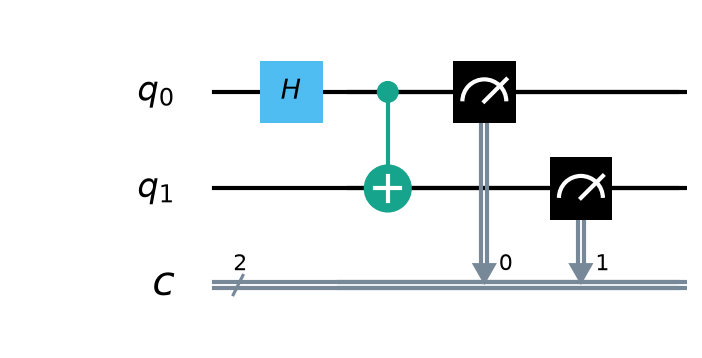

In [5]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day1"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "02_local_simulation.png"
prog.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
